# Isolated EODs: 20 example frames per fish (4-fish, Kaden masks, 10 cm / 5×)

The isolated (sure-emitter) EODs of `fish_pair_factors_iso10cm_dom5/sure_emitter_eods.csv`: the fish's mask midline ≥ 10 cm from
every other fish's; at its top pair p* (largest predicted |v| of that fish, my model) its predicted |v| ≥ 5× every other fish's;
the largest recorded |v| is at p* with the predicted sign; only one fish passes.

**Choice of the 20 frames per fish**, to cover different places in the tank: round-robin over the pairs p* the fish has isolated
EODs at (pairs in order 1–10, repeated until 20 frames); at each pick, among the videos with EODs of that fish at that pair, the one
used least so far for this fish (ties at random), then a random EOD of that video and pair (seed 0; no frame twice).

Each panel: the whole tank (912 × 912 px = 60 cm), Kaden's visible masks of the EOD's video frame (isolated fish in its colour,
the other fish grey with their letter), the electrodes (+ filled, − open, pair number at the + pole), and the pair p* joined by a
line. Title: video, frame, p*, distance (cm) from the isolated fish's midline to the nearest other fish's midline.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from model_voltages_4fish import Masks                                # imports mask_metrics, which sets the Agg backend
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/fish_pair_factors_iso10cm_dom5'
OUT = f'{SRC}/example_frames'; os.makedirs(OUT, exist_ok=True)
KADEN = 'data/track_Kaden/results_{t}_full/video2024-02-20T{t}/outputs/video2024-02-20T{t}.pkl'
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv')
N_PER_FISH = 20

S = pd.read_csv(f'{SRC}/sure_emitter_eods.csv')
rng = np.random.default_rng(0)
picks = []
for f in LET:
    s = S[S.emitter == f]
    pairs = sorted(s['pair p* (1-10)'].unique())
    used_video = {t: 0 for t in s.video.unique()}; taken = set(); j = 0
    while len([p for p in picks if p['emitter'] == f]) < N_PER_FISH:
        p = pairs[j % len(pairs)]; j += 1
        sp = s[(s['pair p* (1-10)'] == p) & ~s.set_index(['video', 'Frame']).index.isin(taken)]
        if sp.empty: continue
        vids = sp.video.unique(); m = min(used_video[v] for v in vids)
        v = rng.choice([v for v in vids if used_video[v] == m])
        r = sp[sp.video == v].sample(1, random_state=rng.integers(1 << 31)).iloc[0]
        used_video[v] += 1; taken.add((r.video, r.Frame)); picks.append(r.to_dict())
PK = pd.DataFrame(picks)
PK.to_csv(f'{OUT}/example_frames_20_per_fish.csv', index=False)
display(pd.crosstab(PK.emitter, PK['pair p* (1-10)'])); display(pd.crosstab(PK.emitter, PK.video))

pair p* (1-10),1,2,3,4,5,6,7,8,9,10
emitter,,,,,,,,,,
A,2,2,2,2,2,2,2,2,2,2
B,3,3,2,2,0,2,2,2,2,2
C,2,2,2,2,2,2,2,2,2,2
D,3,3,2,2,2,2,2,2,0,2


video,05_52_55,06_52_55,11_12_57,15_16_23,19_16_25
emitter,,,,,
A,6,4,2,5,3
B,4,4,4,4,4
C,10,4,0,4,2
D,7,4,3,3,3


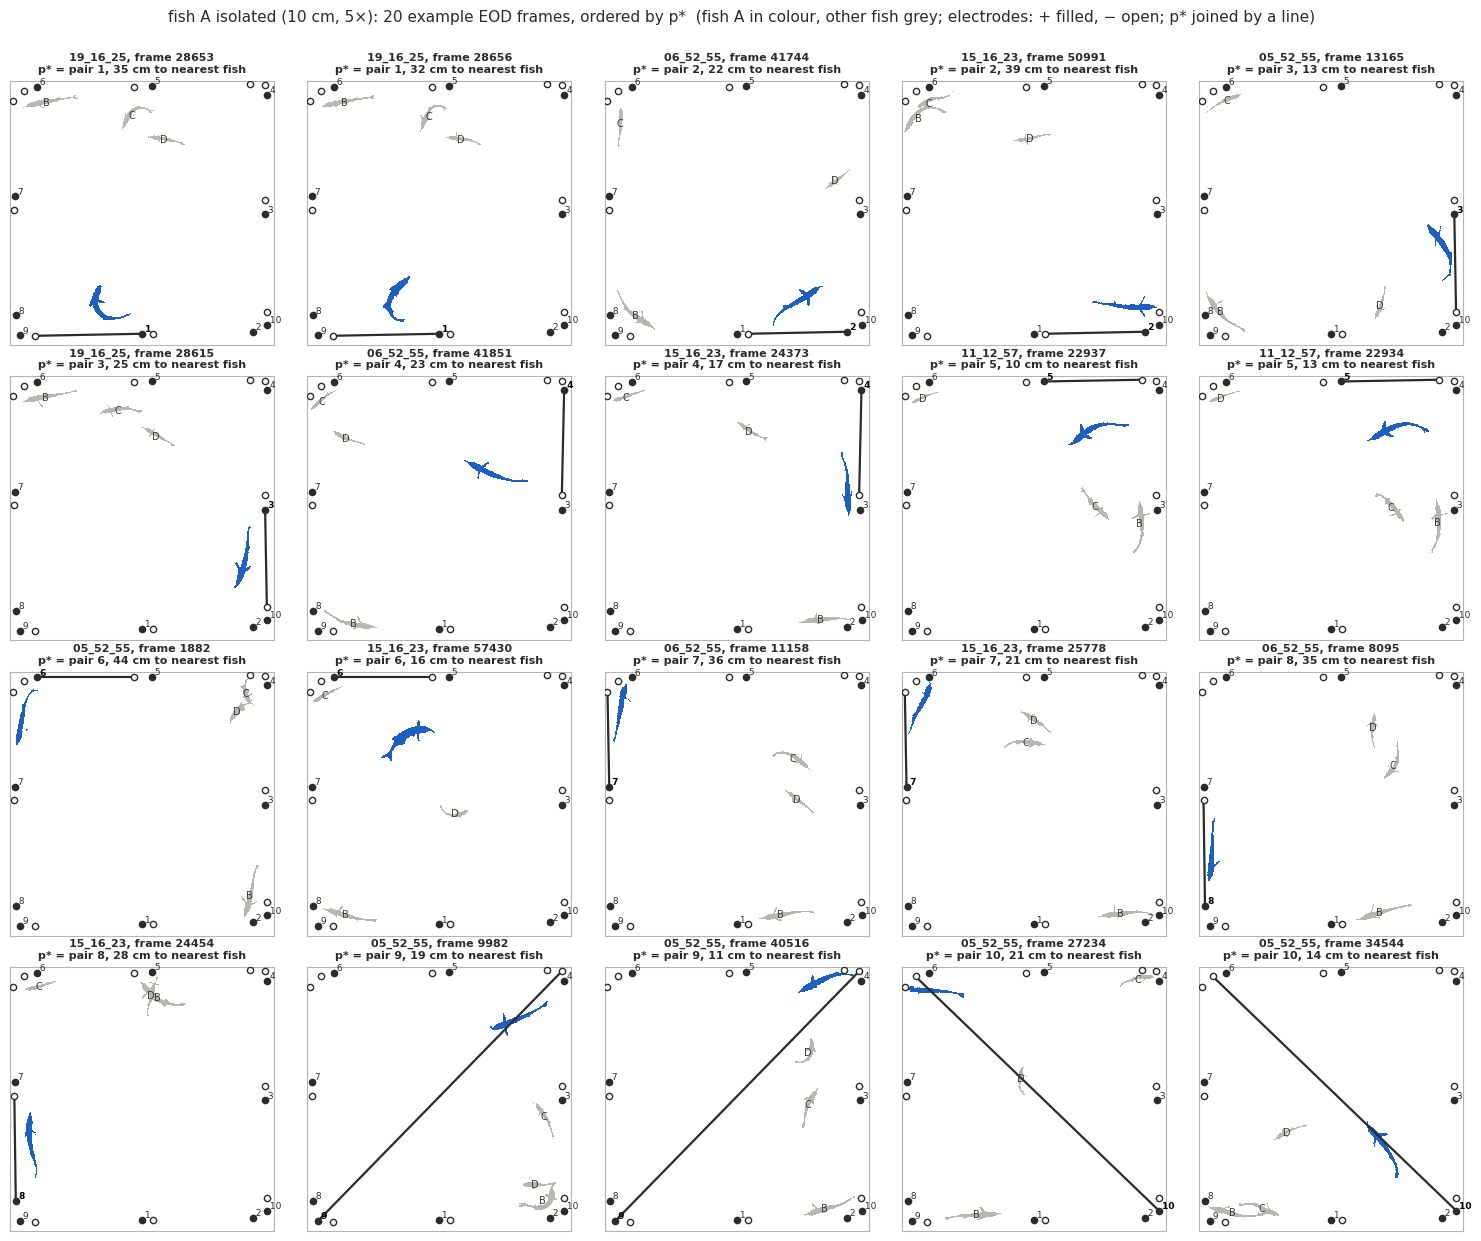

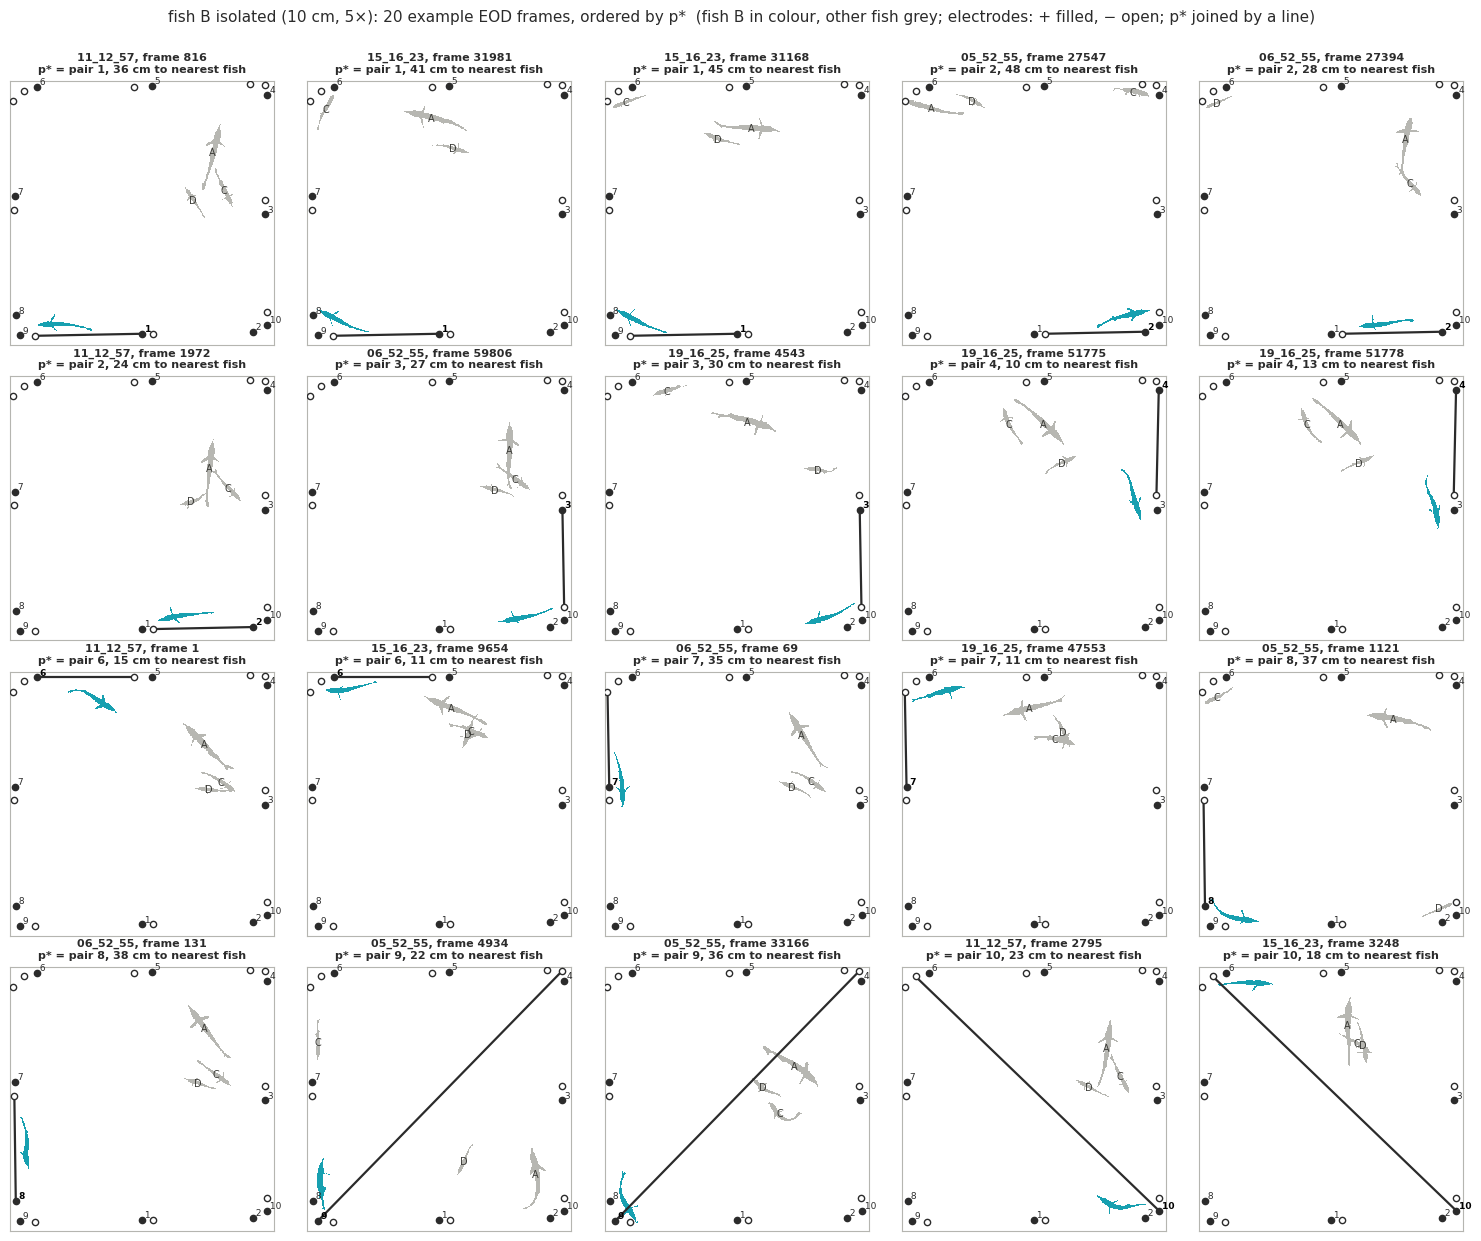

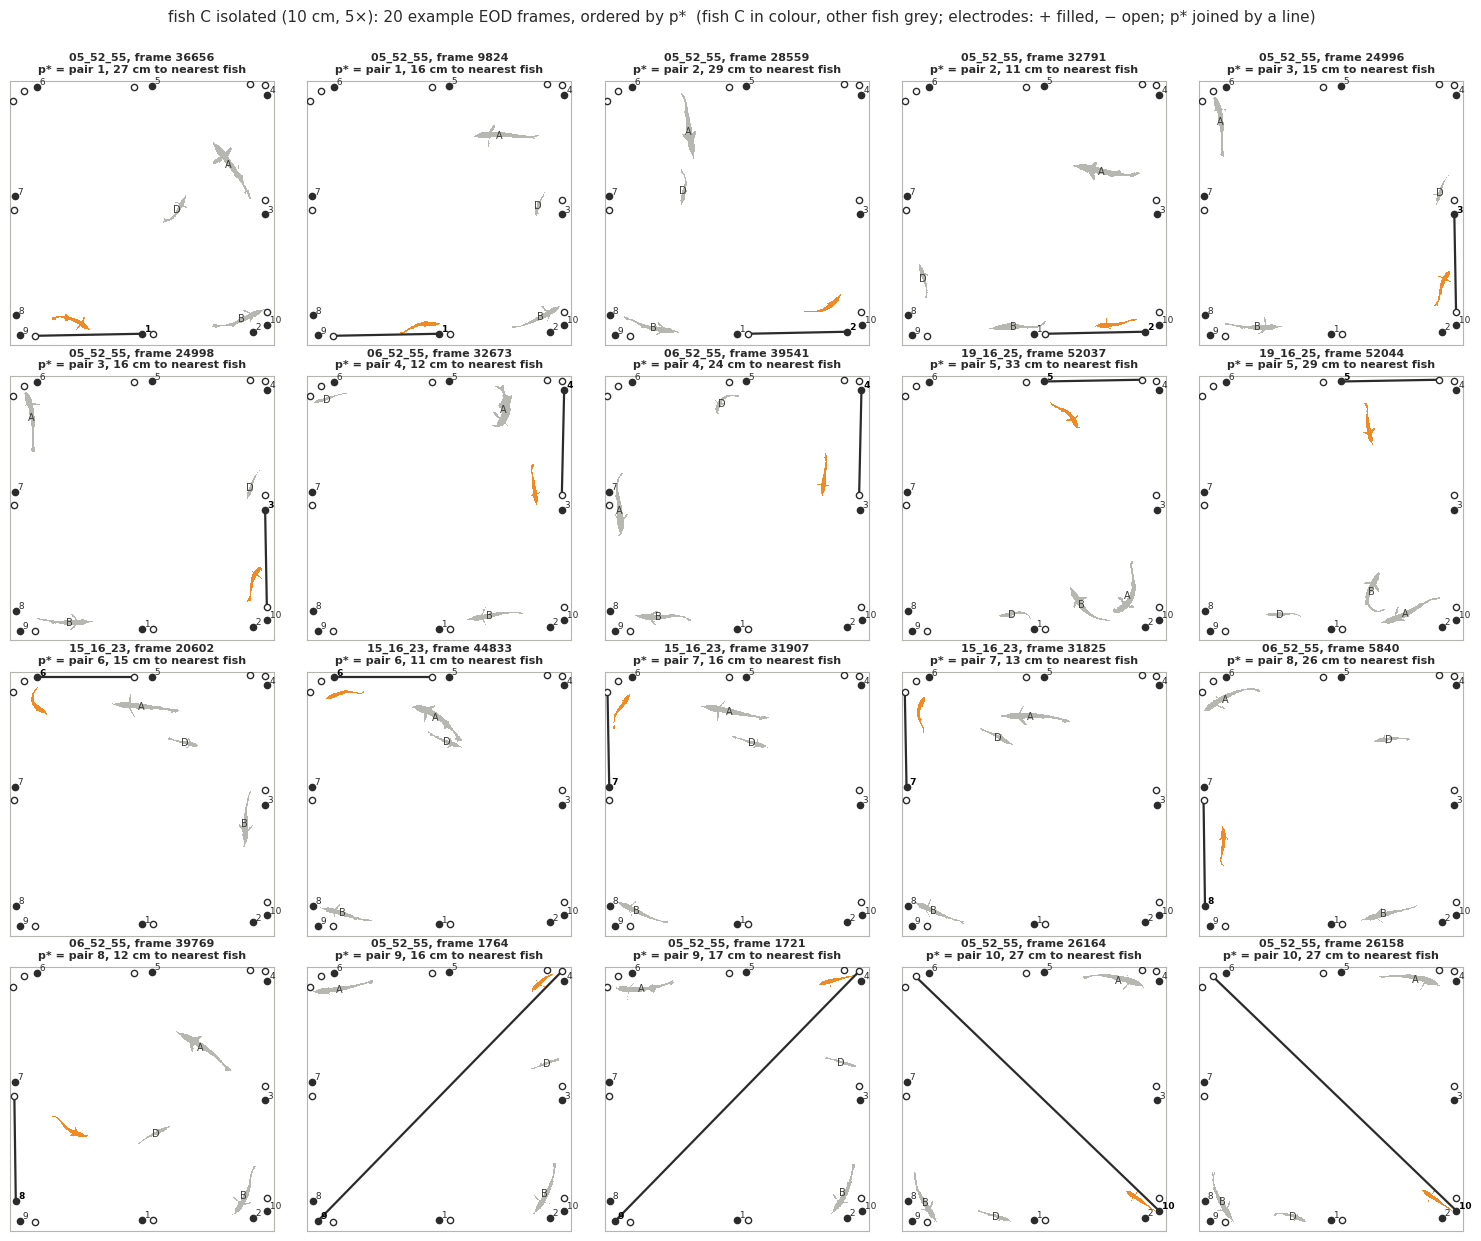

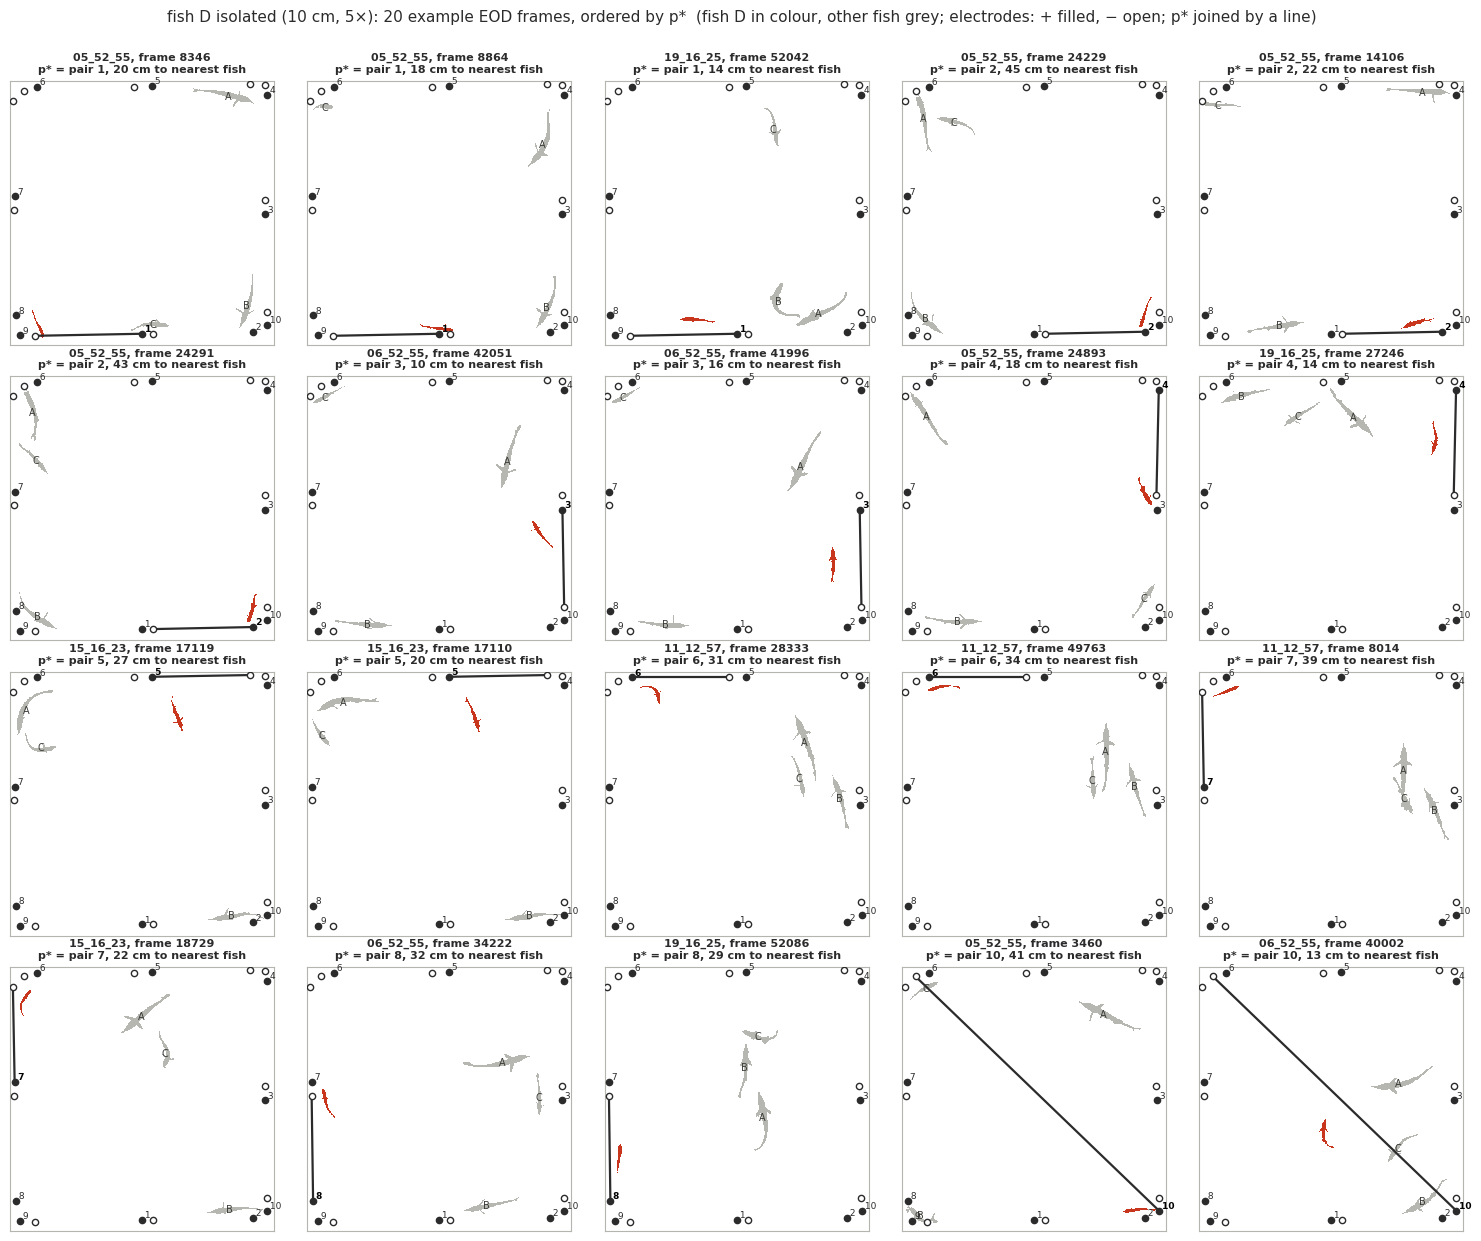

In [2]:
masks = {}
for t in PK.video.unique():
    mk = Masks(dict(identity='kaden', masks=KADEN.format(t=t)))
    for k in PK.Frame[PK.video == t].unique(): masks[(t, int(k))] = mk(int(k))
    del mk

def panel(ax, r):
    m = masks[(r.video, int(r.Frame))]
    img = np.ones((P, P, 3))
    for j, f in enumerate(LET):
        c = to_rgb(FISH_COL[f]) if f == r.emitter else (0.72, 0.72, 0.70)
        img[m[j]] = c
    ax.imshow(img, origin='upper', extent=(0, P, P, 0), interpolation='nearest')
    for j, f in enumerate(LET):
        if f != r.emitter and m[j].any():
            yy, xx = np.nonzero(m[j]); ax.text(xx.mean(), yy.mean(), f, fontsize=7, color='#3a3a36', ha='center', va='center')
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2)
        mm = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        hit = int(e.pair) == int(r['pair p* (1-10)'])
        if hit: ax.plot([pp[0], mm[0]], [pp[1], mm[1]], color='#2b2b2b', lw=1.6, zorder=2)
        ax.plot(*pp, 'o', ms=4.5, color='#2b2b2b', zorder=3)
        ax.plot(*mm, 'o', ms=4.5, mfc='white', mec='#2b2b2b', mew=1, zorder=3)
        ax.text(pp[0], pp[1], f' {int(e.pair)}', fontsize=6.5, color='#2b2b2b' if not hit else '#000000',
                fontweight='bold' if hit else 'normal', va='bottom')
    ax.set(xlim=(0, P), ylim=(P, 0), xticks=[], yticks=[], aspect='equal')
    for s in ax.spines.values(): s.set_visible(True); s.set_color('#b5b5b0')
    ax.set_title(f"{r.video}, frame {int(r.Frame)}\np* = pair {int(r['pair p* (1-10)'])}, {r['gap (cm)']:.0f} cm to nearest fish", fontsize=8)

for f in LET:
    rows = PK[PK.emitter == f].sort_values(['pair p* (1-10)', 'video']).reset_index(drop=True)
    fig, axs = plt.subplots(4, 5, figsize=(15, 12.6))
    for ax, (_, r) in zip(axs.ravel(), rows.iterrows()): panel(ax, r)
    for ax in axs.ravel()[len(rows):]: ax.axis('off')
    fig.suptitle(f'fish {f} isolated (10 cm, 5×): 20 example EOD frames, ordered by p*  '
                 f'(fish {f} in colour, other fish grey; electrodes: + filled, − open; p* joined by a line)', fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.975)); fig.savefig(f'{OUT}/isolated_examples_fish_{f}.png', dpi=110); plt.show()

## Zoomed in on the isolated fish

The same 20 frames per fish, each cropped to a square window centred on the isolated fish's mask (window side = 1.6 × that fish's
length, the same in every panel of a fish, so sizes compare). Mask pixels at full resolution; the fish's mask midline
(`midlines_by_frame.npz`, the one the model used) drawn on top, tail → head, head marked with a dot; other fish's masks and
electrodes inside the window drawn as in the overview. Scale bar: 2 cm.

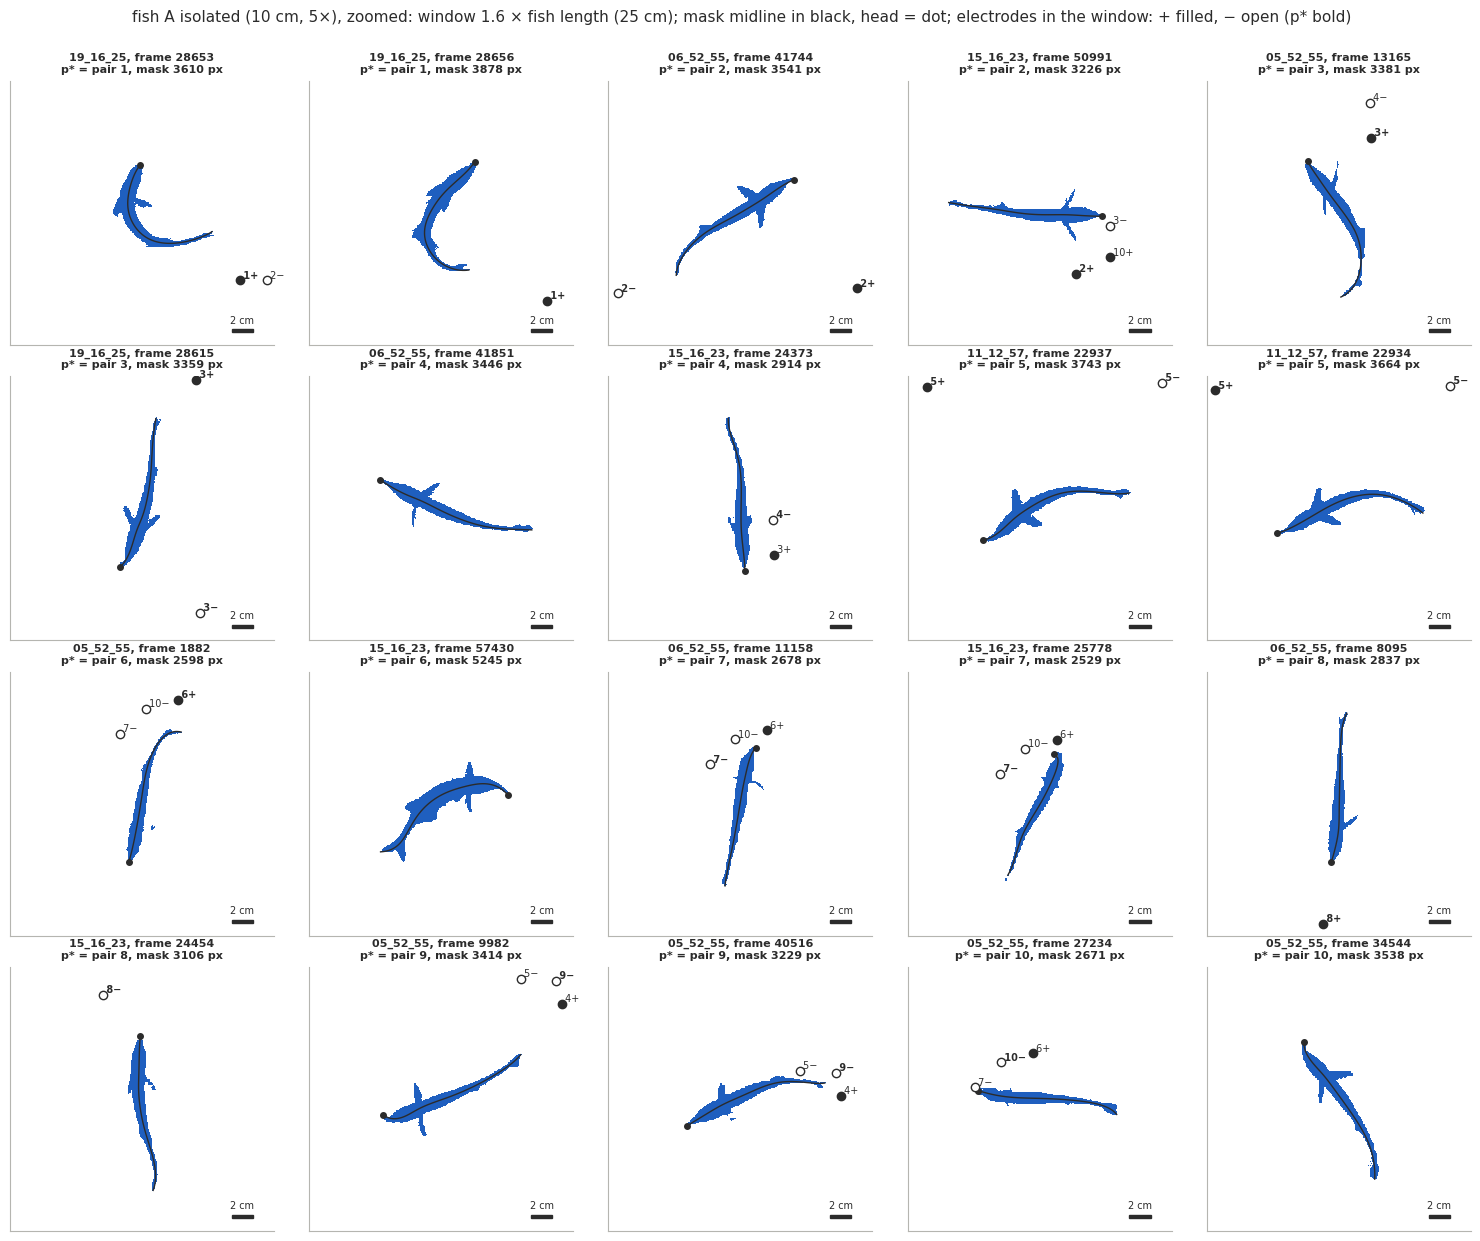

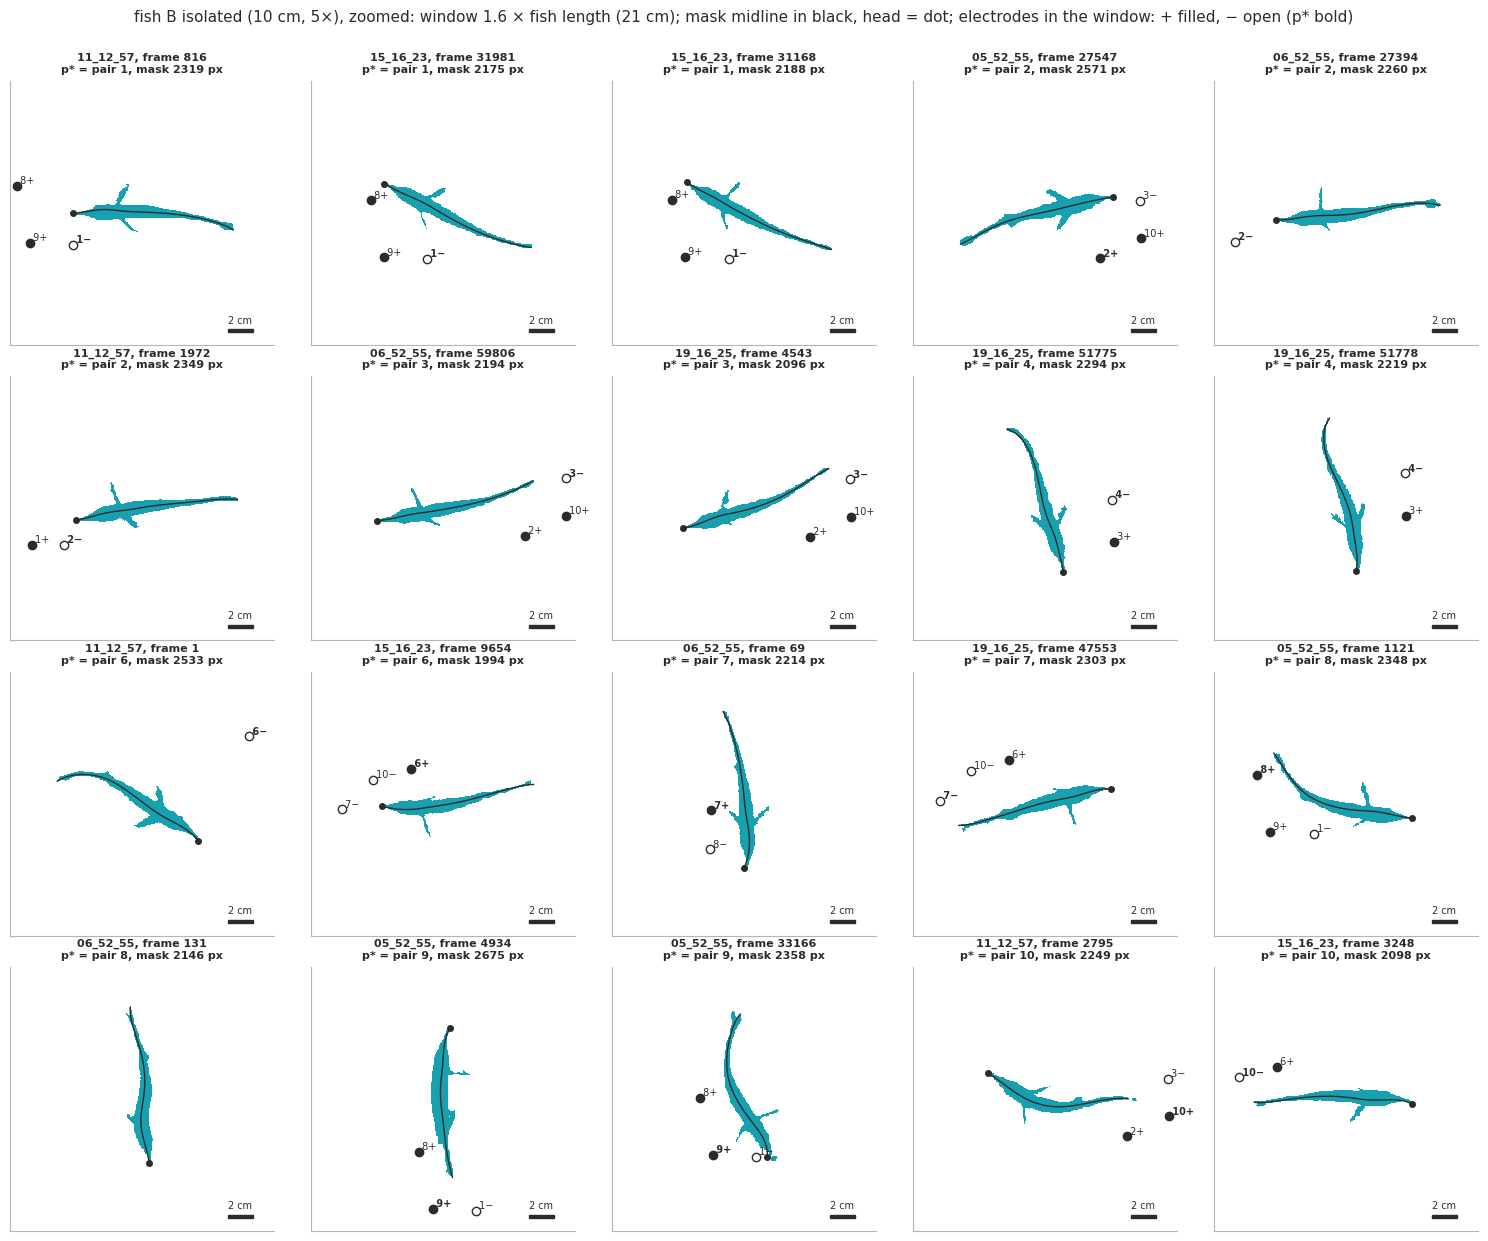

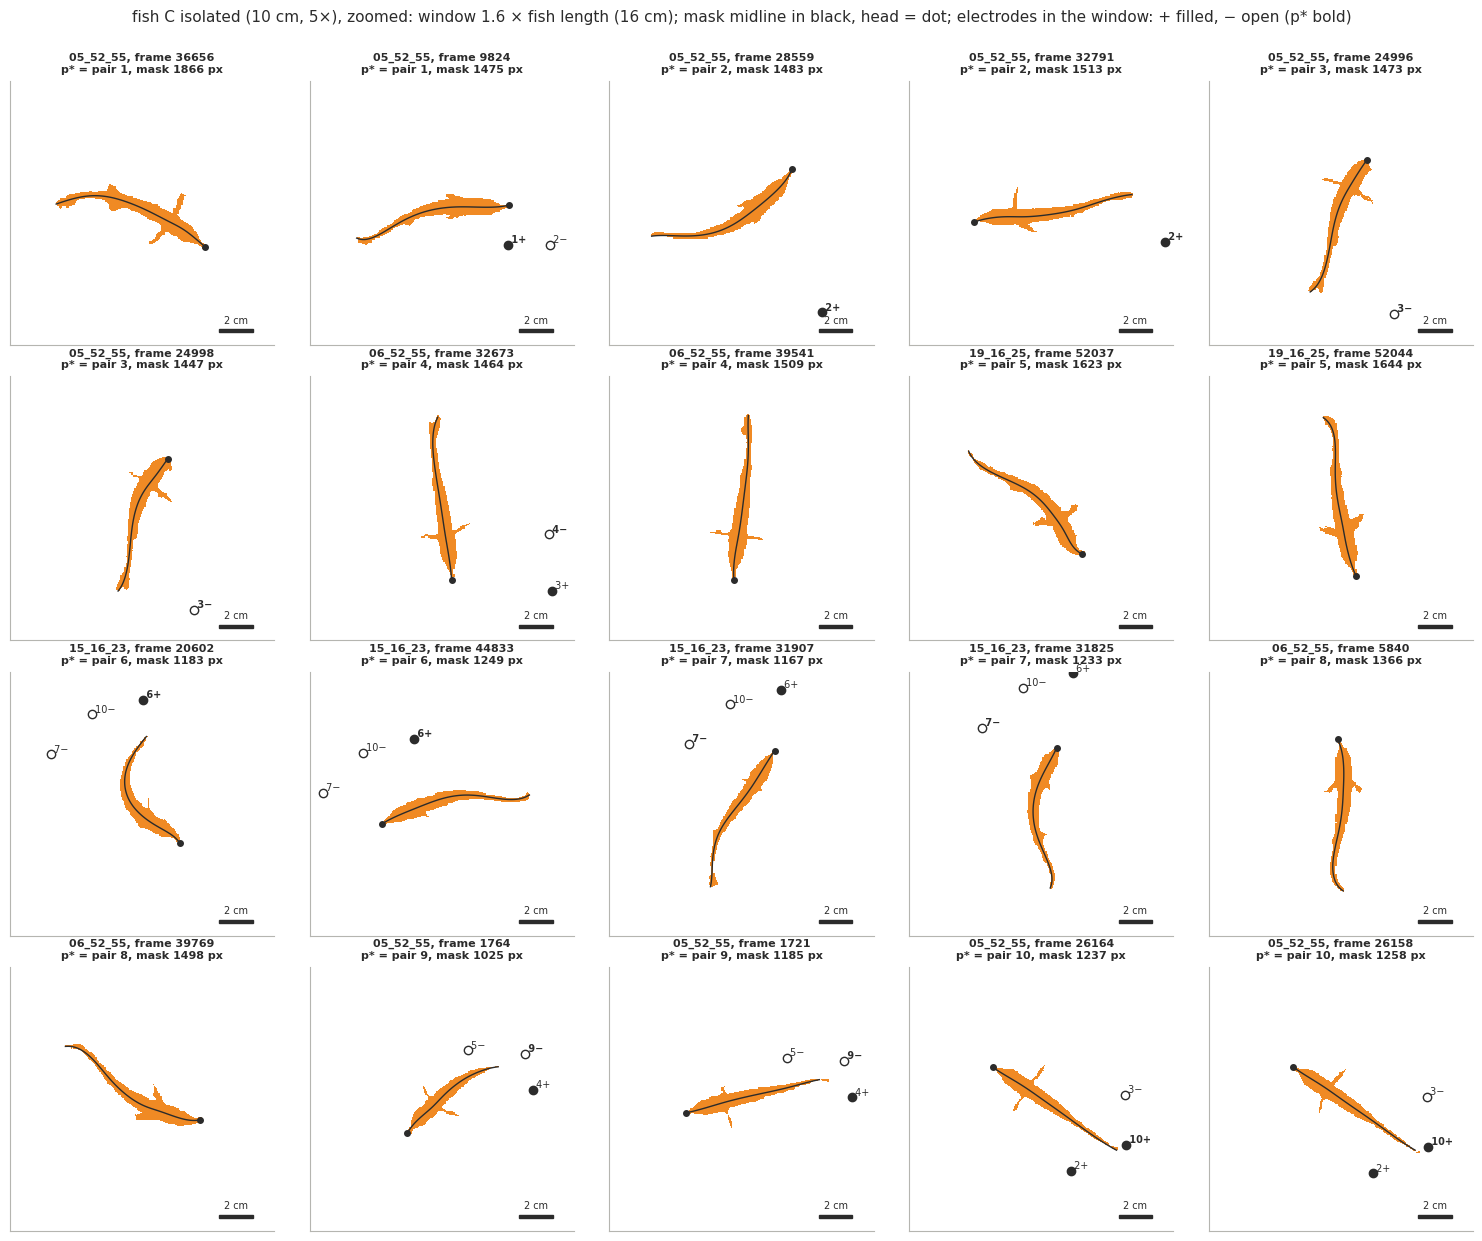

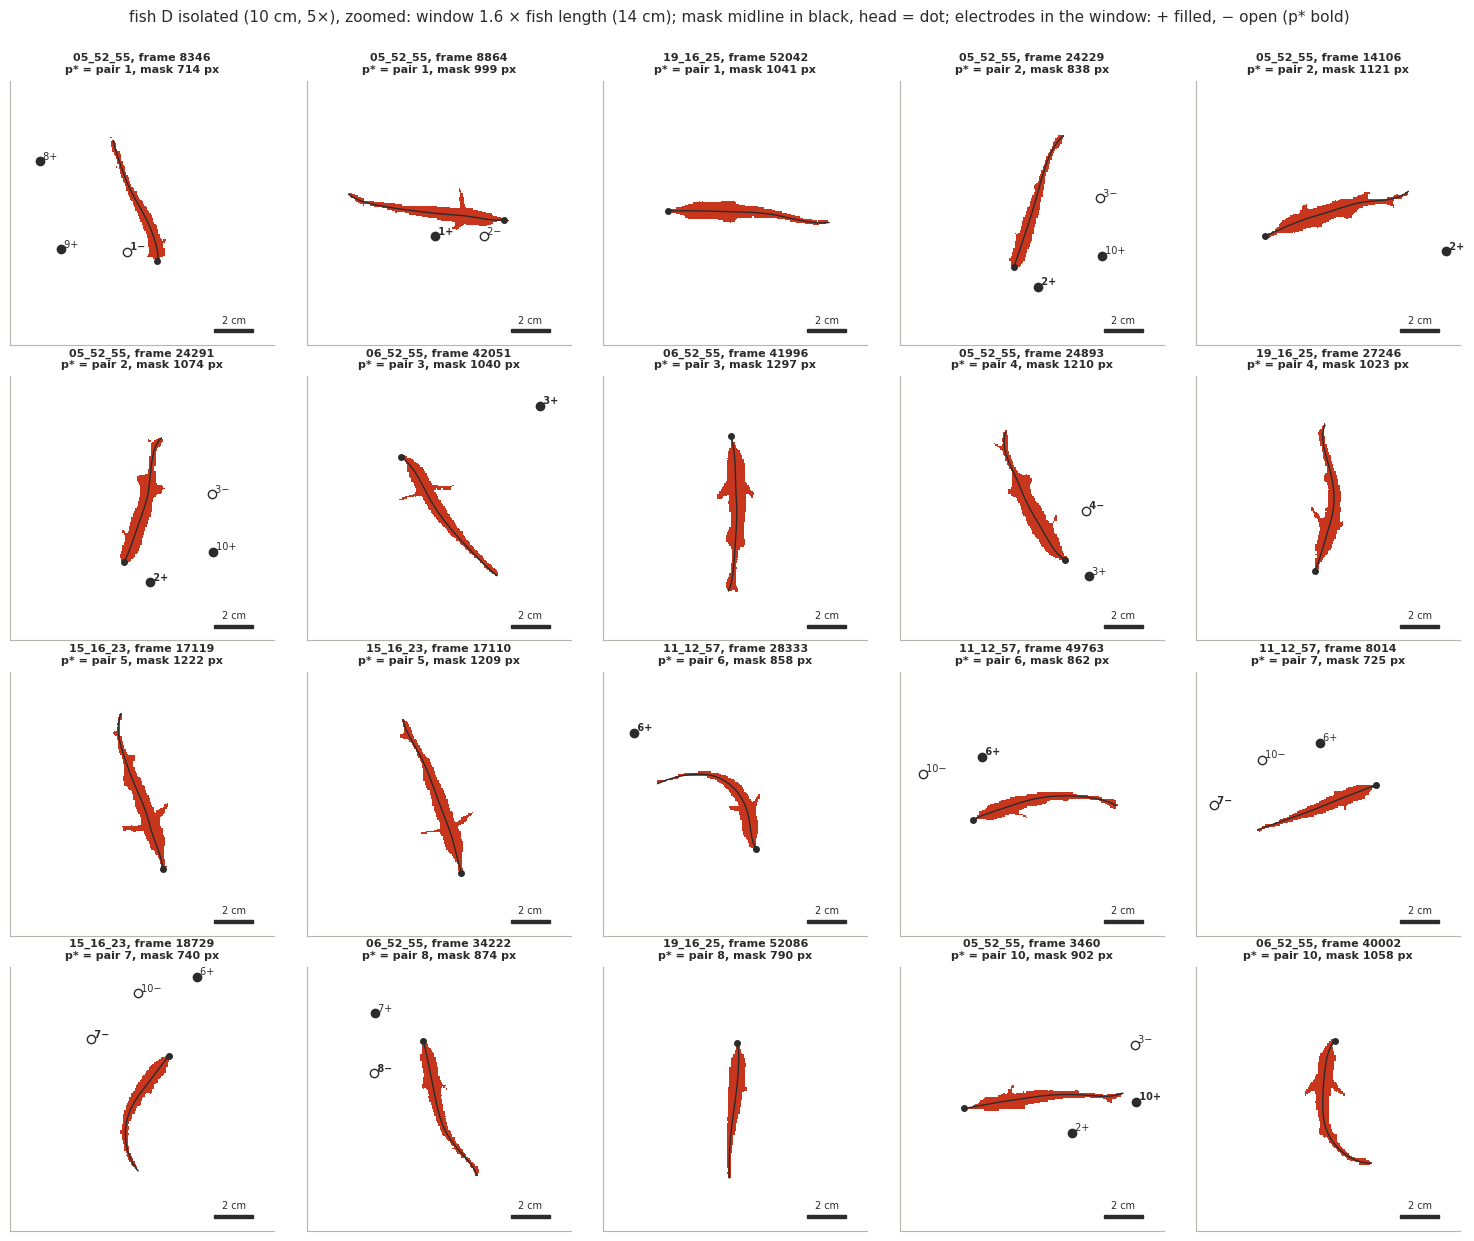

In [3]:
from matplotlib.patches import Rectangle
PX_CM = P / 60
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}                     # 90th percentile of the mask midline (cm)
mids = {}
for t in PK.video.unique():
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); idx = {int(k): i for i, k in enumerate(z['frames'])}
    for k in PK.Frame[PK.video == t].unique(): mids[(t, int(k))] = z['mids'][idx[int(k)]] * (P - 1)   # (4, 101, 2) px (row, col)

def zoom_panel(ax, r):
    m = masks[(r.video, int(r.Frame))]; j = LET.index(r.emitter)
    yy, xx = np.nonzero(m[j]); cy, cx = yy.mean(), xx.mean()
    h = 0.8 * L_CM[r.emitter] * PX_CM                                       # half window
    y0, y1, x0, x1 = cy - h, cy + h, cx - h, cx + h
    img = np.ones((P, P, 3))
    for jj, f in enumerate(LET):
        img[m[jj]] = to_rgb(FISH_COL[f]) if f == r.emitter else (0.72, 0.72, 0.70)
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for jj, f in enumerate(LET):
        if f != r.emitter and m[jj].any():
            ty, tx = np.nonzero(m[jj]); my, mx = ty.mean(), tx.mean()
            if y0 < my < y1 and x0 < mx < x1: ax.text(mx, my, f, fontsize=8, color='#3a3a36', ha='center', va='center')
    ml = mids[(r.video, int(r.Frame))][j]
    if np.isfinite(ml).all():
        ax.plot(ml[:, 1], ml[:, 0], color='#2b2b2b', lw=1)
        ax.plot(ml[-1, 1], ml[-1, 0], 'o', ms=4, color='#2b2b2b')
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2)
        mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        for pt, filled in ((pp, True), (mm_, False)):
            if x0 <= pt[0] <= x1 and y0 <= pt[1] <= y1:
                ax.plot(*pt, 'o', ms=6, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1)
                ax.text(pt[0], pt[1], f' {int(e.pair)}{"+" if filled else "−"}', fontsize=7, color='#2b2b2b', va='bottom',
                        fontweight='bold' if int(e.pair) == int(r['pair p* (1-10)']) else 'normal')
    sb = 2 * PX_CM
    ax.add_patch(Rectangle((x1 - 0.08 * 2 * h - sb, y1 - 0.06 * 2 * h), sb, 0.012 * 2 * h, color='#2b2b2b'))
    ax.text(x1 - 0.08 * 2 * h - sb / 2, y1 - 0.075 * 2 * h, '2 cm', fontsize=7, ha='center', va='bottom', color='#2b2b2b')
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal')
    for sp in ax.spines.values(): sp.set_color('#b5b5b0')
    ax.set_title(f"{r.video}, frame {int(r.Frame)}\np* = pair {int(r['pair p* (1-10)'])}, mask {m[j].sum()} px", fontsize=8)

for f in LET:
    rows = PK[PK.emitter == f].sort_values(['pair p* (1-10)', 'video']).reset_index(drop=True)
    fig, axs = plt.subplots(4, 5, figsize=(15, 12.6))
    for ax, (_, r) in zip(axs.ravel(), rows.iterrows()): zoom_panel(ax, r)
    for ax in axs.ravel()[len(rows):]: ax.axis('off')
    fig.suptitle(f'fish {f} isolated (10 cm, 5×), zoomed: window 1.6 × fish length ({1.6 * L_CM[f]:.0f} cm); '
                 f'mask midline in black, head = dot; electrodes in the window: + filled, − open (p* bold)', fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.975)); fig.savefig(f'{OUT}/isolated_examples_fish_{f}_zoom.png', dpi=110); plt.show()